In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
wine = load_wine()

df = pd.DataFrame(wine.data, columns=wine.feature_names)

print("First Five Records:")
print(df.head())

First Five Records:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  

In [3]:
print("First Five Records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nFeature Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

First Five Records:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  

In [4]:
X = df

y = wine.target

print("Selected Features:")
print(X.head())

print("\nTarget Labels:")
print(y[:5])

print("\nShape of X:")
print(X.shape)

print("\nShape of y:")
print(y.shape)

Selected Features:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  


In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled Features:")
print(X_scaled)

print("\nScaled Data Shape:")
print(X_scaled.shape)

Scaled Features:
[[ 1.51861254 -0.5622498   0.23205254 ...  0.36217728  1.84791957
   1.01300893]
 [ 0.24628963 -0.49941338 -0.82799632 ...  0.40605066  1.1134493
   0.96524152]
 [ 0.19687903  0.02123125  1.10933436 ...  0.31830389  0.78858745
   1.39514818]
 ...
 [ 0.33275817  1.74474449 -0.38935541 ... -1.61212515 -1.48544548
   0.28057537]
 [ 0.20923168  0.22769377  0.01273209 ... -1.56825176 -1.40069891
   0.29649784]
 [ 1.39508604  1.58316512  1.36520822 ... -1.52437837 -1.42894777
  -0.59516041]]

Scaled Data Shape:
(178, 13)


In [6]:
pca = PCA()

X_pca_all = pca.fit_transform(X_scaled)

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nCumulative Explained Variance:")
print(np.cumsum(pca.explained_variance_ratio_))

Explained Variance Ratio:
[0.36198848 0.1920749  0.11123631 0.0706903  0.06563294 0.04935823
 0.04238679 0.02680749 0.02222153 0.01930019 0.01736836 0.01298233
 0.00795215]

Cumulative Explained Variance:
[0.36198848 0.55406338 0.66529969 0.73598999 0.80162293 0.85098116
 0.89336795 0.92017544 0.94239698 0.96169717 0.97906553 0.99204785
 1.        ]


In [7]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

n_components = np.argmax(cumulative_variance >= 0.90) + 1

print("Cumulative Explained Variance:")
print(cumulative_variance)

print("\nNumber of Components Required:")
print(n_components)

print("\nVariance Retained:")
print(round(cumulative_variance[n_components - 1] * 100, 2), "%")

Cumulative Explained Variance:
[0.36198848 0.55406338 0.66529969 0.73598999 0.80162293 0.85098116
 0.89336795 0.92017544 0.94239698 0.96169717 0.97906553 0.99204785
 1.        ]

Number of Components Required:
8

Variance Retained:
92.02 %


In [8]:
pca_2 = PCA(n_components=2)

X_pca = pca_2.fit_transform(X_scaled)

print("Reduced Data:")
print(X_pca)

print("\nReduced Data Shape:")
print(X_pca.shape)

Reduced Data:
[[ 3.31675081  1.44346263]
 [ 2.20946492 -0.33339289]
 [ 2.51674015  1.0311513 ]
 [ 3.75706561  2.75637191]
 [ 1.00890849  0.86983082]
 [ 3.05025392  2.12240111]
 [ 2.44908967  1.17485013]
 [ 2.05943687  1.60896307]
 [ 2.5108743   0.91807096]
 [ 2.75362819  0.78943767]
 [ 3.47973668  1.30233324]
 [ 1.7547529   0.61197723]
 [ 2.11346234  0.67570634]
 [ 3.45815682  1.13062988]
 [ 4.31278391  2.09597558]
 [ 2.3051882   1.66255173]
 [ 2.17195527  2.32730534]
 [ 1.89897118  1.63136888]
 [ 3.54198508  2.51834367]
 [ 2.0845222   1.06113799]
 [ 3.12440254  0.78689711]
 [ 1.08657007  0.24174355]
 [ 2.53522408 -0.09184062]
 [ 1.64498834 -0.51627893]
 [ 1.76157587 -0.31714893]
 [ 0.9900791   0.94066734]
 [ 1.77527763  0.68617513]
 [ 1.23542396 -0.08980704]
 [ 2.18840633  0.68956962]
 [ 2.25610898  0.19146194]
 [ 2.50022003  1.24083383]
 [ 2.67741105  1.47187365]
 [ 1.62857912  0.05270445]
 [ 1.90269086  1.63306043]
 [ 1.41038853  0.69793432]
 [ 1.90382623  0.17671095]
 [ 1.38486223 

In [9]:
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])

print("PCA DataFrame:")
print(pca_df.head())

PCA DataFrame:
        PC1       PC2
0  3.316751  1.443463
1  2.209465 -0.333393
2  2.516740  1.031151
3  3.757066  2.756372
4  1.008908  0.869831


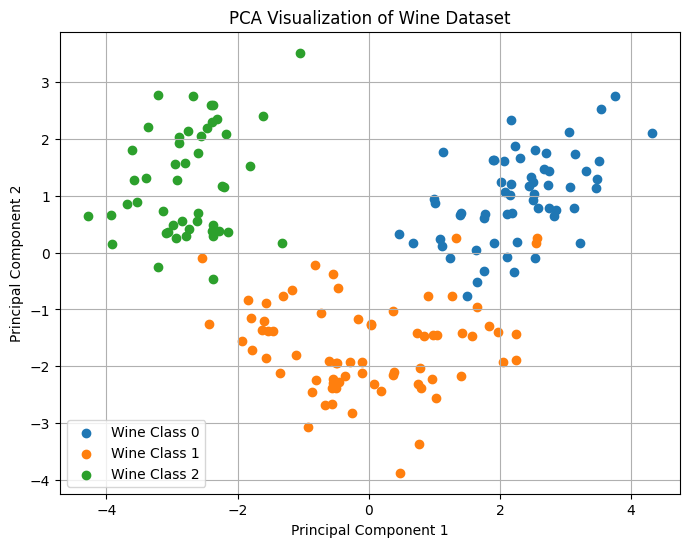

In [10]:
plt.figure(figsize=(8, 6))

for i in np.unique(y):
    plt.scatter(
        pca_df.loc[y == i, "PC1"],
        pca_df.loc[y == i, "PC2"],
        label=f"Wine Class {i}"
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Wine Dataset")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
print("Original Dataset Shape:")
print(X.shape)

print("\nReduced Dataset Shape:")
print(X_pca.shape)

print("\nOriginal Number of Features:", X.shape[1])
print("Reduced Number of Components:", X_pca.shape[1])

Original Dataset Shape:
(178, 13)

Reduced Dataset Shape:
(178, 2)

Original Number of Features: 13
Reduced Number of Components: 2


In [12]:
explained_variance = pca_2.explained_variance_ratio_

print("PC1 Explained Variance:")
print(round(explained_variance[0] * 100, 2), "%")

print("\nPC2 Explained Variance:")
print(round(explained_variance[1] * 100, 2), "%")

print("\nCombined Explained Variance:")
print(round(sum(explained_variance) * 100, 2), "%")

PC1 Explained Variance:
36.2 %

PC2 Explained Variance:
19.21 %

Combined Explained Variance:
55.41 %
